In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import os 
import rasterio

In [ ]:
for i in os.listdir("Maps/organisme/Vigitation/"):
    raster_path = f"Maps/organisme/Vigitation/{i}"
    with rasterio.open(raster_path) as src:
        raster_data = src.read()
        transform = src.transform  
    print(f"================{i}===============")
    print(raster_data)
    print(src.meta)
    print(np.unique(raster_data))


In [ ]:
for i in os.listdir("Maps/organisme/human/"):
    raster_path = f"Maps/organisme/human/{i}"
    with rasterio.open(raster_path) as src:
        raster_data = src.read()
        transform = src.transform  
    print(f"================{i}===============")
    print(raster_data)
    print(src.meta)
    print(np.unique(raster_data))

In [ ]:
for i in os.listdir("Maps/organisme/fauna/"):
    raster_path = f"Maps/organisme/fauna/{i}"
    with rasterio.open(raster_path) as src:
        raster_data = src.read()
        transform = src.transform  
    print(f"================{i}===============")
    print(raster_data)
    print(np.unique(raster_data))

# Data Explanation : 
1. Fauna : all animals distribution (amphibians , birds , mammals , reptiles) the data gives th nombre of birds , mammals ...etc in this area for example each pixel containe 1km²and the value is he number of animals in this area (form 0 --> 153  or 0 --> 178)

2. vegetation : the percentage of a specific land cover  (barren , evergreen, herbaceous) in speicific area (pixel)

3. human activities : gives the human modification in 1km² area between 0 and 1 

we can deduct somethings like : 
- High Species Richness + Low Human Modification → Biodiversity hotspots with low disturbance (ideal for conservation).
- High Species Richness + High Human Modification → Threatened ecosystems (urgent conservation priority).
- Low Species Richness + High Human Modification → Urban/agricultural areas with low ecological value.
- Low Species Richness + Low Human Modification → Natural areas with fewer species (e.g., deserts).

In [3]:
df = pd.read_excel("../results/soil_dataset.xlsx" , sheet_name="soil_data")
df = df.drop(columns=["id" , "id_memoire" , "id_ech" , "Wilaya" , "Region" , "USDA Soil Taxonomy" , "altitude"])
df = df.dropna(subset=["X" , "Y"])
df.fillna(df.mean(), inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1256 entries, 0 to 1255
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   X                   1256 non-null   float64
 1   Y                   1256 non-null   float64
 2   UD                  1256 non-null   int64  
 3   LD                  1256 non-null   int64  
 4   average profondeur  1256 non-null   float64
 5   pH                  1256 non-null   float64
 6   CE                  1256 non-null   float64
 7   CEC                 1256 non-null   float64
 8   A%                  1256 non-null   float64
 9   L%                  1256 non-null   float64
 10  S%                  1256 non-null   float64
 11  ALR(L)              1256 non-null   float64
 12  ALR(S)              1256 non-null   float64
 13  OM                  1256 non-null   float64
dtypes: float64(12), int64(2)
memory usage: 137.5 KB


In [4]:
from rasterio.transform import rowcol
def latlon_to_pixel(lat, lon, dataset ,transform):
    # Validate if the coordinate is within the image bounds
    print(dataset.bounds.left ,  dataset.bounds.right , dataset.bounds.bottom , dataset.bounds.top)
    print(lon , lat)
    if not (dataset.bounds.left <= lon <= dataset.bounds.right and
            dataset.bounds.bottom <= lat <= dataset.bounds.top):
        raise ValueError(f"Coordinates ({lat}, {lon}) are outside the image bounds!")

    # Convert to pixel row & column
    row, col = rowcol(dataset.transform, lon, lat)
    
    return row, col

In [5]:
df_unique = df.copy()
df_unique = df_unique.drop_duplicates(subset=["X" ,"Y"])
df_unique 

,X,Y,UD,LD,average profondeur,pH,CE,CEC,A%,L%,S%,ALR(L),ALR(S),OM
0,3.107000,36.684000,15,30,22.5,7.870,0.170000,17.929000,46.172091,45.613249,8.214660,-0.005289,-0.749790,2.01900
3,3.133330,36.071667,15,30,22.5,7.950,0.260000,40.610953,32.330400,40.460456,27.209144,0.097420,-0.074896,2.64500
5,3.150000,36.724167,15,30,22.5,8.500,2.632808,40.610953,13.000000,32.000000,55.000000,0.391206,0.626419,7.27000
7,2.880278,36.757500,5,15,10.0,8.590,0.370000,40.610953,7.210000,11.570000,81.220000,0.205397,1.051727,4.10000
9,3.178361,36.704083,15,30,22.5,7.830,2.632808,3.750000,27.239966,42.857252,29.902781,0.235311,-0.092333,1.36000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1228,6.899167,36.848333,0,5,2.5,6.458,2.632808,10.271000,24.565243,49.690174,25.744583,0.305949,0.020365,2.81564
1234,6.900000,36.848889,0,5,2.5,6.227,2.632808,6.491000,14.629570,25.312036,60.058394,0.238095,0.613342,1.79740
1240,6.900000,36.846667,0,5,2.5,5.794,2.632808,6.285000,14.045140,38.565386,47.389474,0.438671,0.528155,2.68836
1246,6.903889,36.847222,0,5,2.5,6.362,2.632808,9.667000,22.956000,58.289000,18.755000,0.404690,-0.087779,3.32476


In [38]:
# windows Forming 
def window_forming(raster_path  , df ,height=7 , width=7 ):
    covariable_num = len(os.listdir(raster_path))
    windows = []

    print(f"========================{raster_path}========================")
    for i in range(len(df)) :

        print(f"the dataset is in : {i}") 
        lat =  df.iloc[i]["X"]
        lon = df.iloc[i]["Y"]

        window = np.empty((height, width, covariable_num))
        for index , j in enumerate(os.listdir(raster_path)):
            print(f"========================{j}========================")
            with rasterio.open(f"{raster_path}/{j}") as src :
                raster_data = src.read()
                transform = src.transform 
                print(src.crs)
                print(src.res)
            
            print(raster_data)
            pixel_x ,pixel_y = latlon_to_pixel(lat , lon , src , transform)
            mid = height//2
            try : 
                window[:,:,index] = raster_data[ 0 , pixel_x - mid : pixel_x + mid +1 , pixel_y - mid : pixel_y + mid +1 ]
            except Exception as e:
                print("error is here ")
                print(e)
        
        windows.append(window)
    return windows

In [18]:
# windows Forming 
def window_forming2(raster_path  , df ,height=7 , width=7 ):
    covariable_num = len(os.listdir(raster_path))
    windows = []

    print(f"========================{raster_path}========================")
    for i in range(len(df)) :

        print(f"the dataset is in : {i}") 
        lat =  df.iloc[i]["X"]
        lon = df.iloc[i]["Y"]

        window = np.empty((height, width, covariable_num))
        for index , j in enumerate(os.listdir(raster_path)):
            print(f"========================{j}========================")
            with rasterio.open(f"{raster_path}/{j}") as src :
                raster_data = src.read()
                transform = src.transform 
                print(src.crs)
                print(src.res)
            
            print(raster_data)
            try : 
                pixel_x ,pixel_y = latlon_to_pixel(lat , lon , src , transform)
                mid = height//2
                window[:,:,index] = raster_data[ 0 , pixel_x - mid : pixel_x + mid +1 , pixel_y - mid : pixel_y + mid +1 ]
                break 
            except Exception as e :
                continue 
        
        windows.append(window)
    return windows

In [ ]:
vegetation_window = window_forming("Maps/organisme/Vigitation" , df_unique)

========================Maps/organisme/Vigitation========================
the dataset is in : 0
========================barren.tif========================
[[42 47 42 53 49 53 55]
 [56 58 59 54 58 49 37]
 [54 72 67 47 52 53 61]
 [45 65 43 46 51 53 54]
 [59 77 53 57 61 60 54]
 [53 94 47 61 54 48 58]
 [48 45 42 45 54 54 49]]
========================cultivated.tif========================
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]
========================deciduousTrees.tif========================
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]
========================evergreen.tif========================
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]
========================herbaceous.tif========================
[[13 12 13 10 10 11 10]
 [21 10 10 15  8 13 13]
 [ 8  8  0  8

In [13]:
fauna_windows = window_forming("Maps/organisme/fauna" , df_unique)
human_window = window_forming("Maps/organisme/human" , df_unique)

========================Maps/organisme/fauna========================
the dataset is in : 0
========================amphibians.tif========================
[[255 255 255 255 255 255 255]
 [255 255 255 255 255 255 255]
 [255 255 255 255 255 255 255]
 [255 255 255 255 255 255 255]
 [255 255 255 255 255 255 255]
 [255 255 255 255 255 255 255]
 [255 255 255 255 255 255 255]]
========================birds.tif========================
[[65535 65535 65535 65535 65535 65535 65535]
 [65535 65535 65535 65535 65535 65535 65535]
 [65535 65535 65535 65535 65535 65535 65535]
 [65535 65535 65535 65535 65535 65535 65535]
 [65535 65535 65535 65535 65535 65535 65535]
 [65535 65535 65535 65535 65535 65535 65535]
 [65535 65535 65535 65535 65535 65535 65535]]
========================mammals.tif========================
[[96 96 96 96 96 96 96]
 [96 96 96 96 96 96 96]
 [96 96 96 96 96 96 96]
 [96 96 96 96 96 96 96]
 [96 96 96 96 96 96 96]
 [96 96 96 96 96 96 96]
 [96 96 96 96 96 96 96]]
========================r

In [14]:
veg_window = np.array(vegetation_window)

In [15]:
veg_window.shape

(177, 7, 7, 11)

In [16]:
fa_window = np.array(fauna_windows)
fa_window.shape

(177, 7, 7, 4)

In [17]:
hu_window = np.array(human_window)
hu_window.shape

(177, 7, 7, 1)

In [18]:
np.save("vegetation.npy", veg_window)
np.save("fauna.npy", fa_window)
np.save("human_activities.npy", hu_window)

In [9]:
relief_window = window_forming("Maps/relief/" , df_unique)
np.save("Data_multi_CNN/relief.npy", relief_window) 

========================Maps/relief/========================
the dataset is in : 0
========================Aspect_cos.tif========================
[[-4.5358694e-01  2.1048810e-01  4.5500207e-01  7.3650634e-01
   4.0531707e-01  3.7709808e-01 -3.1923592e-01]
 [ 8.6571538e-01  9.8058069e-01  9.2568970e-01  3.6517990e-01
   1.9261378e-01 -1.3817124e-02 -3.0170053e-01]
 [-7.0062983e-01 -3.5914427e-01 -5.0968933e-01 -5.7766950e-01
  -8.7405801e-02 -2.1718327e-02 -6.8142630e-02]
 [-1.2966529e-01 -7.8230035e-01 -4.9792206e-01 -5.2817744e-01
   4.0214220e-01  4.4639763e-01  1.2748680e-01]
 [-3.1292310e-01 -3.1622744e-01 -3.4031314e-01 -3.2898641e-01
   1.0354033e-01  3.8941637e-01  1.4586388e-01]
 [-3.0009991e-01  3.1189460e-02 -1.8025729e-01 -2.1413937e-01
  -6.1541587e-01  3.3982229e-01  3.4993470e-01]
 [-7.8086948e-01 -8.5945725e-01 -4.9089056e-01 -7.4629955e-02
  -1.1528941e-01  3.1391647e-07  3.6518511e-01]]
========================Aspect_East.tif========================
[[ 0.5333216   0.53

In [41]:
np.array(relief_window)[0][:,:,7]

IndexError: index 7 is out of bounds for axis 2 with size 7

In [32]:
np.array(relief_window)[1][:,:,5]

array([[2. , 3. , 2.5, 3. , 4. , 4. , 4. ],
       [2.5, 3. , 3. , 4. , 3. , 4.5, 4. ],
       [2. , 4. , 3. , 3. , 2. , 4. , 3. ],
       [4. , 5. , 5. , 4. , 5. , 4. , 3.5],
       [5. , 6. , 5.5, 3. , 3. , 5.5, 4. ],
       [6.5, 7.5, 6.5, 8.5, 7. , 6.5, 5. ],
       [7. , 5. , 5. , 7.5, 7. , 8. , 7. ]])

### landuse

In [ ]:
landuse_window = window_forming("Maps/SpatialPosition/landuse" , df_unique)
np.save("landuse.npy", landuse_window)
landuse_window

========================Maps/SpatialPosition/landuse========================
the dataset is in : 0
========================40N_000E.tif========================
EPSG:4326
(0.00025, 0.00025)
[[[250 250 250 ... 254 254 254]
  [253 253 250 ... 254 254 254]
  [253 253 250 ... 254 254 254]
  ...
  [  0   0   0 ...   0   0   0]
  [  0   0   0 ...   0   0   0]
  [  0   0   0 ...   0   0   0]]]
0.0 10.0 30.0 40.0
3.107 36.684
[[250 250 250 250 250 252 252]
 [250 250 250 250 252 244 244]
 [250 250 250 250 244 244 244]
 [253 250 250  23 244 244 244]
 [244 244 247 247 244 244 244]
 [244 244 247 247 244 244 244]
 [244 244 244 247 244 244 244]]
the dataset is in : 1
========================40N_000E.tif========================
EPSG:4326
(0.00025, 0.00025)
[[[250 250 250 ... 254 254 254]
  [253 253 250 ... 254 254 254]
  [253 253 250 ... 254 254 254]
  ...
  [  0   0   0 ...   0   0   0]
  [  0   0   0 ...   0   0   0]
  [  0   0   0 ...   0   0   0]]]
0.0 10.0 30.0 40.0
3.13333 36.0716666
[[ 20  20  

[array([[[250.],
         [250.],
         [250.],
         [250.],
         [250.],
         [252.],
         [252.]],
 
        [[250.],
         [250.],
         [250.],
         [250.],
         [252.],
         [244.],
         [244.]],
 
        [[250.],
         [250.],
         [250.],
         [250.],
         [244.],
         [244.],
         [244.]],
 
        [[253.],
         [250.],
         [250.],
         [ 23.],
         [244.],
         [244.],
         [244.]],
 
        [[244.],
         [244.],
         [247.],
         [247.],
         [244.],
         [244.],
         [244.]],
 
        [[244.],
         [244.],
         [247.],
         [247.],
         [244.],
         [244.],
         [244.]],
 
        [[244.],
         [244.],
         [244.],
         [247.],
         [244.],
         [244.],
         [244.]]]),
 array([[[ 20.],
         [ 20.],
         [ 19.],
         [ 18.],
         [ 18.],
         [ 18.],
         [ 18.]],
 
        [[ 17.],
       

In [21]:
water_window = window_forming2("Maps/SpatialPosition/waterBodies/needed" , df_unique)
np.save("water.npy", water_window)
water_window

========================Maps/SpatialPosition/waterBodies/needed========================
the dataset is in : 0
========================n00e035_hnd.tif========================
EPSG:4326
(0.0008333333333333334, 0.0008333333333333334)
[[[0.00000000e+00 5.00000000e-01 6.00006104e-01 ... 1.85000000e+01
   1.72000732e+01 8.90002441e+00]
  [0.00000000e+00 7.00012207e-01 1.99981689e-01 ... 4.01999512e+01
   2.63000488e+01 1.58000488e+01]
  [0.00000000e+00 3.00018311e-01 0.00000000e+00 ... 3.00999756e+01
   2.72999268e+01 2.08999023e+01]
  ...
  [1.07900024e+02 2.30099976e+02 2.31199951e+02 ... 6.00006104e-01
   0.00000000e+00 0.00000000e+00]
  [1.67199951e+02 1.57099976e+02 1.74199951e+02 ... 4.00009155e-01
   5.00000000e-01 3.00003052e-01]
  [1.21299927e+02 1.10000000e+02 1.21000000e+02 ... 5.00000000e-01
   8.99993896e-01 8.00003052e-01]]]
34.999583333333334 39.999583333333334 -0.0004166666666662877 4.999583333333334
36.684 3.107
the dataset is in : 1
========================n00e035_hnd.tif==

[array([[[2.29998779e+000, 1.46574368e-311, 1.46557805e-311,
          6.95282494e-310],
         [1.29998779e+000, 1.46566554e-311, 6.95282494e-310,
          1.46574369e-311],
         [3.19995117e+000, 6.95282494e-310, 1.46574369e-311,
          1.46555658e-311],
         [1.17000122e+001, 1.46555658e-311, 1.46566554e-311,
          1.46557876e-311],
         [1.16000366e+001, 1.46555658e-311, 1.46566554e-311,
          1.46557876e-311],
         [1.15000000e+001, 1.46555658e-311, 1.46555658e-311,
          6.95282494e-310],
         [1.06000366e+001, 6.95282494e-310, 6.95282494e-310,
          1.46574369e-311]],
 
        [[2.20001221e+000, 6.95282494e-310, 6.95282494e-310,
          6.95282494e-310],
         [0.00000000e+000, 6.95282494e-310, 1.46554705e-311,
          1.46566554e-311],
         [1.09997559e+000, 1.46555658e-311, 1.46555658e-311,
          1.46555658e-311],
         [9.60003662e+000, 1.46554705e-311, 1.46566554e-311,
          1.46557876e-311],
         [8.700012

In [25]:
np.array(water_window).shape

(177, 7, 7, 4)

### geoMorphology

In [ ]:
import geopandas as gpd
shapefile_path = "Maps/ParentMaterial/Geomorphology/Algeria/Algeria_HG.shp"
gdf = gpd.read_file(shapefile_path)
gdf["category_numeric"], category_mapping = gdf["AlgGLG"].factorize()

gdf

,AlgGLG,AlgHGComb,geometry,category_numeric
0,Cenozoic marine sedimentary,CSIF-M/H,"POLYGON ((8.45253 36.74774, 8.44275 36.74145, ...",0
1,Cenozoic Volcanic,I-L,"POLYGON ((7.33742 37.04831, 7.34198 37.03628, ...",1
2,Cretaceous sedimentary - North,CSIFK-H/VH,"POLYGON ((7.40476 37.02045, 7.40095 36.98996, ...",2
3,Cenozoic Volcanic,I-L,"POLYGON ((6.42381 37.0474, 6.42708 37.00076, 6...",1
4,Cambrian to Silurian sedimentary,CSIF-M/H,"POLYGON ((6.53423 37.00874, 6.51115 37.01278, ...",3
...,...,...,...,...
2155,Cambrian to Silurian sedimentary,CSIF-M/H,"POLYGON ((5.99503 26.52211, 6.03816 26.48939, ...",3
2156,Cretaceous sedimentary - North,CSIFK-H/VH,"POLYGON ((1.73399 36.55842, 1.71555 36.53553, ...",2
2157,Recent-Quaternary unconsolidated sediments,U-H(*),"POLYGON ((0.42299 36.14992, 0.40639 36.12363, ...",5
2158,Recent-Quaternary unconsolidated sediments,U-H(*),"POLYGON ((0.26749 36.06518, 0.26356 36.03167, ...",5


In [1]:
gdf["category_numeric"].value_counts()

NameError: name 'gdf' is not defined

In [ ]:
bounds = gdf.total_bounds  
print("Bounds:", bounds)
resolution = 0.008983  
width = int((bounds[2] - bounds[0]) / resolution)
height = int((bounds[3] - bounds[1]) / resolution)

print(f"Raster size: Width={width}, Height={height}")

Bounds: [-8.67386818 18.96003151 11.98891068 37.08087102]
Raster size: Width=2300, Height=2017


In [ ]:
import rasterio
import numpy as np
from rasterio.transform import from_bounds
from rasterio.features import rasterize


transform = from_bounds(*bounds, width, height)
raster = rasterize(
    [(geom, value) for geom, value in zip(gdf.geometry, gdf["category_numeric"])],
    out_shape=(height, width),
    transform=transform,
    fill=-1, 
    dtype=rasterio.int32
)

tiff_path = "output_1km.tif"
with rasterio.open(
    tiff_path, "w", 
    driver="GTiff",
    height=height, 
    width=width, 
    count=1,
    dtype=rasterio.uint8,
    crs=gdf.crs,  # Use same CRS as shapefile
    transform=transform
) as dst:
    dst.write(raster, 1)

print(f"Saved 1 km raster to {tiff_path}")

Saved 1 km raster to output_1km.tif


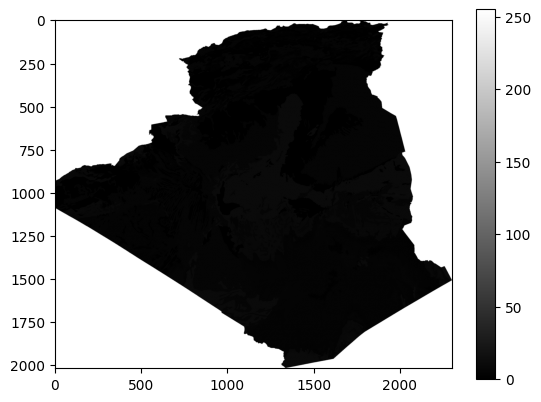

In [ ]:
import matplotlib.pyplot as plt

with rasterio.open(tiff_path) as dataset:
    img = dataset.read(1)  # Read the first band
    plt.imshow(img, cmap="gray")
    plt.colorbar()
    plt.show()

In [ ]:
geoMorpho_window = window_forming2("Maps/ParentMaterial/Geomorphology/tiff" , df_unique)
np.save("geoMorpho.npy", geoMorpho_window)
geoMorpho_window

========================Maps/ParentMaterial/Geomorphology/tiff========================
the dataset is in : 0
========================output_1km.tif========================
EPSG:4326
(0.00898381689565216, 0.008984055283252787)
[[[255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]
  ...
  [255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]]]
-8.67386818000005 11.988910679999918 18.960031509999993 37.08087101632086
36.684 3.107
the dataset is in : 1
========================output_1km.tif========================
EPSG:4326
(0.00898381689565216, 0.008984055283252787)
[[[255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]
  ...
  [255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]]]
-8.67386818000005 11.988910679999918 18.960031509999993 37.08087101632086
36.0716666 3.13333
the dataset is in : 2
========================output_1k

[array([[[0.],
         [0.],
         [0.],
         [0.],
         [0.],
         [0.],
         [0.]],
 
        [[0.],
         [0.],
         [0.],
         [0.],
         [0.],
         [0.],
         [0.]],
 
        [[0.],
         [0.],
         [0.],
         [0.],
         [0.],
         [0.],
         [0.]],
 
        [[0.],
         [0.],
         [0.],
         [0.],
         [0.],
         [0.],
         [0.]],
 
        [[0.],
         [0.],
         [0.],
         [0.],
         [0.],
         [0.],
         [0.]],
 
        [[0.],
         [0.],
         [0.],
         [0.],
         [0.],
         [0.],
         [0.]],
 
        [[0.],
         [0.],
         [0.],
         [0.],
         [0.],
         [0.],
         [0.]]]),
 array([[[-0.60602345],
         [35.70238617],
         [-0.60088487],
         [35.67921493],
         [-0.63574518],
         [35.63814949],
         [-0.67185786]],
 
        [[35.60287471],
         [-0.70348345],
         [35.58829004],
 

In [ ]:
class optimizerKhefoufi:
    def __init__(self , raster_data , transforme , src ):
        self.raster_data = raster_data
        self.transform = transforme
        self.src = src
    

def data_saver(path):
    files = []
    lat_min = 0 
    lat_max = 10

    lon_min = 30
    lon_max = 40


    for i in os.listdir(path):
        print(i)
        with rasterio.open(f"{path}/{i}") as src :
            raster_data = src.read()
            transform = src.transform 

            pixel_minx , pixel_miny = latlon_to_pixel(lat_min , lon_min ,src, transform)
            pixel_maxx , pixel_maxy = latlon_to_pixel(lat_max , lon_max , src , transform)
            print(pixel_minx , pixel_maxx , pixel_miny , pixel_maxy)
            
            raster_data = raster_data[0 , pixel_minx : pixel_maxx , pixel_miny : pixel_maxy]

            tiff_val = optimizerKhefoufi(raster_data , transform , src)
        files.append(tiff_val)
    return files

all_files = data_saver("../Maps/organisme/Microbial/SoilResp_HeterotrophicResp_1928/data")

soil_Rh_mean.tif
-180.0 179.9999985600001 -90.00000000000006 89.99999928
30 0
-180.0 179.9999985600001 -90.00000000000006 89.99999928
40 10
10799 9599 25200 26400
soil_Rs_CV.tif
-180.0 179.9999985600001 -90.00000000000006 89.99999928
30 0
-180.0 179.9999985600001 -90.00000000000006 89.99999928
40 10
10799 9599 25200 26400
soil_Rs_mean.tif
-180.0 179.9999985600001 -90.00000000000006 89.99999928
30 0
-180.0 179.9999985600001 -90.00000000000006 89.99999928
40 10
10799 9599 25200 26400
soil_Rs_SD.tif
-180.0 179.9999985600001 -90.00000000000006 89.99999928
30 0
-180.0 179.9999985600001 -90.00000000000006 89.99999928
40 10
10799 9599 25200 26400


In [ ]:
def window_forming(all_files  , df ,height=7 , width=7 ):
    covariable_num = len(all_files)
    windows = []
    for i in range(len(df)) :
        print(f"the dataset is in : {i}") 
        lat =  df.iloc[i]["X"]
        lon = df.iloc[i]["Y"]

        window = np.empty((height, width, covariable_num))

        for index , i in enumerate(all_files):
            raster_data = i.raster_data
            pixel_x ,pixel_y = latlon_to_pixel(lat , lon ,  i.src , i.transform)
            print(pixel_x , pixel_y)
            mid = height//2
            try : 
                window[:,:,index] = raster_data[ pixel_x - mid : pixel_x + mid +1 , pixel_y - mid : pixel_y + mid +1 ]
            except Exception as e:
                print("error is here ")
                print(e)
        windows.append(window)
    return windows

In [ ]:
Microbial_window = window_forming(all_files , df_unique)
np.save("microbial.npy", Microbial_window)
Microbial_window

the dataset is in : 0
-180.0 179.9999985600001 -90.00000000000006 89.99999928
36.684 3.107
10427 26002
error is here 
could not broadcast input array from shape (0,0) into shape (7,7)
-180.0 179.9999985600001 -90.00000000000006 89.99999928
36.684 3.107
10427 26002
error is here 
could not broadcast input array from shape (0,0) into shape (7,7)
-180.0 179.9999985600001 -90.00000000000006 89.99999928
36.684 3.107
10427 26002
error is here 
could not broadcast input array from shape (0,0) into shape (7,7)
-180.0 179.9999985600001 -90.00000000000006 89.99999928
36.684 3.107
10427 26002
error is here 
could not broadcast input array from shape (0,0) into shape (7,7)
the dataset is in : 1
-180.0 179.9999985600001 -90.00000000000006 89.99999928
36.0716666 3.13333
10424 25928
error is here 
could not broadcast input array from shape (0,0) into shape (7,7)
-180.0 179.9999985600001 -90.00000000000006 89.99999928
36.0716666 3.13333
10424 25928
error is here 
could not broadcast input array from s

[array([[[9.67392419e-312, 9.67392419e-312, 9.67474265e-312,
          6.95288193e-310],
         [9.67392420e-312, 9.67471696e-312, 6.95288193e-310,
          9.67392418e-312],
         [9.67387367e-312, 6.95288193e-310, 9.67392418e-312,
          9.67365313e-312],
         [6.95288193e-310, 9.67365313e-312, 9.67471696e-312,
          9.67387367e-312],
         [9.67365313e-312, 9.67365313e-312, 9.67471696e-312,
          9.67387367e-312],
         [9.67365313e-312, 9.67365313e-312, 9.67365313e-312,
          6.95288193e-310],
         [6.95288193e-310, 6.95288193e-310, 6.95288193e-310,
          9.67475212e-312]],
 
        [[9.67355761e-312, 6.95288193e-310, 6.95288193e-310,
          6.95288193e-310],
         [6.95288193e-310, 6.95288193e-310, 9.67355761e-312,
          9.67471696e-312],
         [9.67387367e-312, 9.67365313e-312, 9.67365313e-312,
          9.67365313e-312],
         [9.67355761e-312, 9.67355761e-312, 9.67471696e-312,
          9.67387367e-312],
         [9.673653

2.Lat Lon

In [8]:
from rasterio.transform import xy
def pixel_to_latlon(row, col, dataset):
    lon, lat = xy(dataset.transform, row, col)
    return lat, lon

In [21]:
windows = []
raster_data_used = "../Maps/organisme/vigitation/evergreen.tif"
with rasterio.open(raster_data_used) as src: 
    raster = src.read()
    transform = src.transform

    for index in range(len(df_unique)):
        lat = df_unique.iloc[index]["X"]
        lon = df_unique.iloc[index]["Y"]

        pixel_row, pixel_col = latlon_to_pixel(lat, lon, src, transform)
        window = np.zeros((7, 7, 2))  # Only initialize once

        for i in range(pixel_row - 3, pixel_row + 4):  # rows (Y)
            for j in range(pixel_col - 3, pixel_col + 4):  # cols (X)
                lat_val, lon_val = pixel_to_latlon(i, j, src)

                row_idx = i - (pixel_row - 3)
                col_idx = j - (pixel_col - 3)

                window[row_idx, col_idx, 0] = lat_val
                window[row_idx, col_idx, 1] = lon_val

        windows.append(window)

# Check result
print(windows[0].shape)

-180.00000000000003 180.00000000000003 -56.000000000000014 90.00000000000001
36.684 3.107
-180.00000000000003 180.00000000000003 -56.000000000000014 90.00000000000001
36.0716666 3.13333
-180.00000000000003 180.00000000000003 -56.000000000000014 90.00000000000001
36.72416667 3.15
-180.00000000000003 180.00000000000003 -56.000000000000014 90.00000000000001
36.7575 2.880277778
-180.00000000000003 180.00000000000003 -56.000000000000014 90.00000000000001
36.70408333 3.178361111
-180.00000000000003 180.00000000000003 -56.000000000000014 90.00000000000001
36.70531667 3.15955
-180.00000000000003 180.00000000000003 -56.000000000000014 90.00000000000001
36.68388889 3.101388889
-180.00000000000003 180.00000000000003 -56.000000000000014 90.00000000000001
34.72694444 6.273938889
-180.00000000000003 180.00000000000003 -56.000000000000014 90.00000000000001
34.71834444 6.306361111
-180.00000000000003 180.00000000000003 -56.000000000000014 90.00000000000001
34.63508056 5.101466667
-180.00000000000003 1

In [23]:
np.array(windows).shape

(177, 7, 7, 2)

In [24]:
np.save("../Data_multi_CNN/latlon.npy", windows)

### Rocks Type 

In [31]:
import geopandas as gpd
shapefile_path = "../Maps/ParentMaterial/Rock_type/geo7_2ag.shp"
gdf = gpd.read_file(shapefile_path)
gdf["category_numeric"], category_mapping = gdf["GLG"].factorize()

gdf

,AREA,PERIMETER,GEO2_7G_,GEO2_7G_ID,GLG,geometry,category_numeric
0,2250.44404,966.65344,2,11939,SEA,"POLYGON ((5.40701 5.57146, 5.4109 5.4694, 5.42...",0
1,1.60529,7.58497,3,6,oth,"POLYGON ((15.64759 40.00266, 15.66 40, 15.676 ...",1
2,7.02790,33.05255,4,3,oth,"POLYGON ((19.89965 39.96591, 22.81549 39.8342,...",1
3,0.06592,1.66218,5,7,oth,"POLYGON ((19.67681 39.78778, 19.7106 39.7867, ...",1
4,0.90818,4.50544,6,4,oth,"POLYGON ((8.40944 39.76892, 9.63446 39.84441, ...",1
...,...,...,...,...,...,...,...
11972,0.01677,0.69987,11974,11935,SO,"POLYGON ((19.69988 -34.58595, 19.70456 -34.581...",31
11973,0.00456,0.35706,11975,11936,D,"POLYGON ((19.69988 -34.58595, 19.70059 -34.602...",27
11974,0.00239,0.20456,11976,11934,pCm,"POLYGON ((19.43258 -34.60229, 19.40437 -34.627...",11
11975,0.00641,0.35766,11977,11938,SO,"POLYGON ((19.84761 -34.67162, 19.85932 -34.661...",31


In [28]:
gdf["GLG"].value_counts()

GLG
T       1364
pCm     1287
Qe      1065
Q        934
K        856
Mi       669
Ti       525
Kl       500
QT       469
Qp       464
H2O      300
J        272
Tr       251
D        213
KC       203
C        202
Qv       198
OCm      197
PC       189
KJ       186
oth      154
S        136
Du       122
Jl       115
MiPi     113
S_d       96
TrP       95
Cm        92
SO        82
O         80
JTr       79
CD        72
P         72
Kimb      63
DS        57
TK        51
JC        49
Pi        47
Mz        22
Pz        21
PzpC       5
MzPz       5
SEA        4
Trl        1
Name: count, dtype: int64

In [32]:
bounds = gdf.total_bounds  
print("Bounds:", bounds)
resolution = 0.008983  
width = int((bounds[2] - bounds[0]) / resolution)
height = int((bounds[3] - bounds[1]) / resolution)

print(f"Raster size: Width={width}, Height={height}")

Bounds: [-22.41335255 -38.57487571  64.54036522  40.00386699]
Raster size: Width=9679, Height=8747


In [33]:
import rasterio
import numpy as np
from rasterio.transform import from_bounds
from rasterio.features import rasterize


transform = from_bounds(*bounds, width, height)
raster = rasterize(
    [(geom, value) for geom, value in zip(gdf.geometry, gdf["category_numeric"])],
    out_shape=(height, width),
    transform=transform,
    fill=-1, 
    dtype=rasterio.int32
)

tiff_path = "rocksType_1km.tif"
with rasterio.open(
    tiff_path, "w", 
    driver="GTiff",
    height=height, 
    width=width, 
    count=1,
    dtype=rasterio.uint8,
    crs=gdf.crs,  # Use same CRS as shapefile
    transform=transform
) as dst:
    dst.write(raster, 1)

print(f"Saved 1 km raster to {tiff_path}")

Saved 1 km raster to rocksType_1km.tif


In [39]:
rocks_window = window_forming("../Maps/ParentMaterial/Rock_type/tiff", df_unique)
np.save("rocks.npy", rocks_window)
rocks_window

========================../Maps/ParentMaterial/Rock_type/tiff========================
the dataset is in : 0
========================rocksType_1km.tif========================
EPSG:4326
(0.008983750156557061, 0.008983507796489746)
[[[255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]
  ...
  [255 255 255 ...   0   0   0]
  [255 255 255 ...   0   0   0]
  [255 255 255 ...   0   0   0]]]
-22.4133525492225 64.5403652160933 -38.574875710885514 40.0038669850103
36.684 3.107
the dataset is in : 1
========================rocksType_1km.tif========================
EPSG:4326
(0.008983750156557061, 0.008983507796489746)
[[[255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]
  [255 255 255 ... 255 255 255]
  ...
  [255 255 255 ...   0   0   0]
  [255 255 255 ...   0   0   0]
  [255 255 255 ...   0   0   0]]]
-22.4133525492225 64.5403652160933 -38.574875710885514 40.0038669850103
36.0716666 3.13333
the dataset is in : 2
========================rocksT

[array([[[6.],
         [6.],
         [6.],
         [6.],
         [6.],
         [6.],
         [6.]],
 
        [[6.],
         [6.],
         [6.],
         [6.],
         [6.],
         [6.],
         [6.]],
 
        [[6.],
         [6.],
         [6.],
         [6.],
         [6.],
         [6.],
         [6.]],
 
        [[6.],
         [6.],
         [6.],
         [6.],
         [6.],
         [6.],
         [6.]],
 
        [[6.],
         [6.],
         [6.],
         [6.],
         [6.],
         [6.],
         [6.]],
 
        [[6.],
         [6.],
         [6.],
         [6.],
         [6.],
         [6.],
         [6.]],
 
        [[6.],
         [6.],
         [6.],
         [6.],
         [6.],
         [6.],
         [6.]]]),
 array([[[5.],
         [5.],
         [5.],
         [5.],
         [5.],
         [5.],
         [5.]],
 
        [[5.],
         [5.],
         [5.],
         [5.],
         [5.],
         [5.],
         [5.]],
 
        [[5.],
         [5.]